# 06 — So sánh Baseline (A0) vs Model cuối (v4)

**Mục tiêu:** Đánh giá công bằng hai mô hình detection trên **cùng protocol**, rồi phân tích cải tiến / hạn chế cho báo cáo.

| Model | Checkpoint | Vai trò |
|-------|------------|--------|
| **Baseline A0** | `baseline_exports/yolov8n_baseline_best.pt` | Mốc so sánh (YOLOv8n, augment mặc định) |
| **Final v4** | `v4_exports/yolov8s_v4_best.pt` | Bản cải tiến (YOLOv8s + aug mạnh + xoay/oversample + ảnh cam thật) |

**Protocol cố định**
1. Cùng split Roboflow: `datasets/vn_currency_yolo_bbox` (train/valid/test)
2. Đánh giá chính: **imgsz=640**, conf mặc định Ultralytics khi `val`
3. Chọn / phân tích ngưỡng trên **validation**; **test chỉ báo cáo sau khi khóa**
4. Bổ sung: eval v4 ở imgsz=800 (cấu hình deploy thực tế)
5. Không dùng test để chọn model

## 0. Import & cấu hình

In [1]:
from __future__ import annotations

from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import yaml
from ultralytics import YOLO

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR = Path(".").resolve()
PROJECT_DIR = NOTEBOOK_DIR.parent
EXPORT_DIR = NOTEBOOK_DIR / "compare_exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

DATA_YAML = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "data.yaml"
assert DATA_YAML.exists(), f"Thiếu {DATA_YAML} — chạy convert dataset trước"

BASE_PT = NOTEBOOK_DIR / "baseline_exports" / "yolov8n_baseline_best.pt"
FINAL_PT = NOTEBOOK_DIR / "v4_exports" / "yolov8s_v4_best.pt"
assert BASE_PT.exists(), BASE_PT
assert FINAL_PT.exists(), FINAL_PT

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)
CLASS_NAMES = list(data_cfg["names"])
# Đảm bảo path trong yaml đúng máy hiện tại
data_cfg["path"] = str((PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox").resolve())
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False, allow_unicode=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
FAIR_IMGSZ = 640          # protocol so sánh chính
DEPLOY_IMGSZ = 800        # imgsz train/deploy của v4
VAL_SPLIT = "val"
TEST_SPLIT = "test"

print("DEVICE :", DEVICE)
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
print("DATA   :", DATA_YAML)
print("BASE   :", BASE_PT)
print("FINAL  :", FINAL_PT)
print("Classes:", CLASS_NAMES)

DEVICE : 0
GPU    : NVIDIA GeForce RTX 5060
DATA   : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/data.yaml
BASE   : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/baseline_exports/yolov8n_baseline_best.pt
FINAL  : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/v4_exports/yolov8s_v4_best.pt
Classes: ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']


## 1. Hàm đánh giá & trích metric

In [2]:
def extract_metrics(metrics, class_names=CLASS_NAMES) -> dict:
    box = metrics.box
    out = {
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
        "precision": float(box.mp),
        "recall": float(box.mr),
    }
    # F1 macro gần đúng từ P/R tổng
    p, r = out["precision"], out["recall"]
    out["f1"] = float(0.0 if (p + r) == 0 else 2 * p * r / (p + r))

    if getattr(box, "ap50", None) is not None:
        ap50 = np.array(box.ap50).reshape(-1)
        for i, name in enumerate(class_names):
            if i < len(ap50):
                out[f"AP50_{name}"] = float(ap50[i])
    return out


def run_val(weights: Path, split: str, imgsz: int, conf: float = 0.25, name: str = "model") -> dict:
    model = YOLO(str(weights))
    metrics = model.val(
        data=str(DATA_YAML),
        split=split,
        imgsz=imgsz,
        conf=conf,
        device=DEVICE,
        plots=False,
        verbose=False,
    )
    out = extract_metrics(metrics)
    out["model"] = name
    out["split"] = split
    out["imgsz"] = imgsz
    out["conf"] = conf
    return out


print("OK helpers")

OK helpers


## 2. Metric đã lưu khi train (tham chiếu nhanh)

In [3]:
rows_saved = []
for label, csv_path in [
    ("A0 baseline", NOTEBOOK_DIR / "baseline_exports" / "baseline_val_metrics.csv"),
    ("v2", NOTEBOOK_DIR / "v2_exports" / "v2_val_metrics.csv"),
    ("v3", NOTEBOOK_DIR / "v3_exports" / "v3_val_metrics.csv"),
    ("v4 final", NOTEBOOK_DIR / "v4_exports" / "v4_val_metrics.csv"),
]:
    if csv_path.exists():
        d = pd.read_csv(csv_path).iloc[0].to_dict()
        rows_saved.append({
            "model": label,
            "val_mAP50": d.get("val_mAP50"),
            "val_mAP50-95": d.get("val_mAP50-95"),
            "val_precision": d.get("val_precision"),
            "val_recall": d.get("val_recall"),
            "source": str(csv_path.name),
        })

saved_df = pd.DataFrame(rows_saved)
display(saved_df)
saved_df.to_csv(EXPORT_DIR / "saved_train_val_metrics_history.csv", index=False)

print(
    "Ghi chú: các số trên đo lúc train (imgsz/conf có thể khác nhau).\n"
    "Bảng so sánh chính thức nằm ở mục 3–4 (cùng protocol)."
)

,model,val_mAP50,val_mAP50-95,val_precision,val_recall,source
0,A0 baseline,0.994649,0.931480,0.989089,0.995300,baseline_val_metrics.csv
1,v2,0.993818,0.866929,0.987712,0.998943,v2_val_metrics.csv
2,v3,0.994854,0.861327,0.990711,0.998683,v3_val_metrics.csv
3,v4 final,0.993986,0.890809,0.993468,0.997710,v4_val_metrics.csv


Ghi chú: các số trên đo lúc train (imgsz/conf có thể khác nhau).
Bảng so sánh chính thức nằm ở mục 3–4 (cùng protocol).


## 3. Đánh giá công bằng trên VALIDATION (imgsz=640)

Đây là bảng dùng để **so model / giải thích cải tiến**. Checkpoint đã chọn từ trước theo quá trình train (không chọn lại bằng test).

Evaluating baseline on VAL...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 122.7±30.8 MB/s, size: 39.7 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/valid/labels.cache... 439 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 439/439 167.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 16.3it/s 1.7s0.1s
                   all        439       1074      0.991      0.996      0.995      0.931
Speed: 0.3ms preprocess, 2.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Evaluating final v4 on VAL...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 g

,model,split,imgsz,conf,mAP50,mAP50-95,precision,recall,f1
0,A0 YOLOv8n baseline,val,640,0.25,0.9946,0.9310,0.9909,0.9955,0.9932
1,v4 YOLOv8s final,val,640,0.25,0.9949,0.8941,0.9960,0.9972,0.9966


Final − Baseline (VAL, imgsz=640):
  delta_mAP50: +0.0003
  delta_mAP50-95: -0.0369
  delta_precision: +0.0052
  delta_recall: +0.0017
  delta_f1: +0.0034


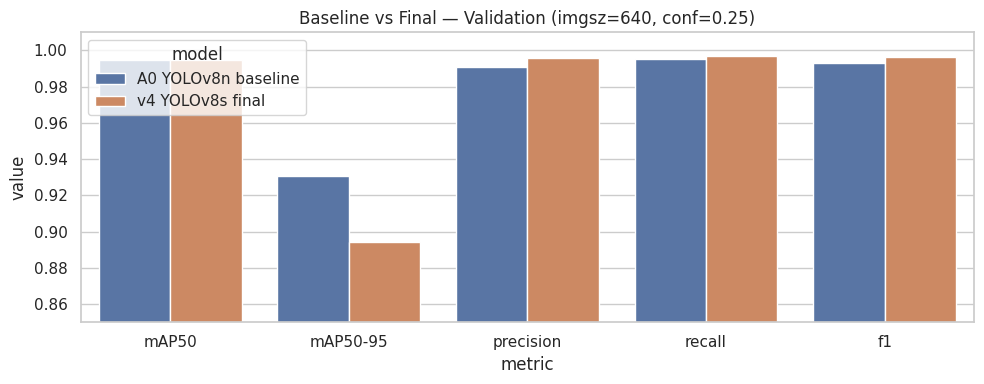

In [4]:
EVAL_CONF = 0.25  # conf cố định khi so backbone/data recipe

print("Evaluating baseline on VAL...")
base_val = run_val(BASE_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="A0 YOLOv8n baseline")
print("Evaluating final v4 on VAL...")
final_val = run_val(FINAL_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="v4 YOLOv8s final")

val_cmp = pd.DataFrame([base_val, final_val])[
    ["model", "split", "imgsz", "conf", "mAP50", "mAP50-95", "precision", "recall", "f1"]
]
display(val_cmp.round(4))
val_cmp.to_csv(EXPORT_DIR / "fair_val_compare_imgsz640.csv", index=False)

# Delta
delta = {
    "delta_mAP50": final_val["mAP50"] - base_val["mAP50"],
    "delta_mAP50-95": final_val["mAP50-95"] - base_val["mAP50-95"],
    "delta_precision": final_val["precision"] - base_val["precision"],
    "delta_recall": final_val["recall"] - base_val["recall"],
    "delta_f1": final_val["f1"] - base_val["f1"],
}
print("Final − Baseline (VAL, imgsz=640):")
for k, v in delta.items():
    print(f"  {k}: {v:+.4f}")

melt = val_cmp.melt(
    id_vars=["model"],
    value_vars=["mAP50", "mAP50-95", "precision", "recall", "f1"],
    var_name="metric",
    value_name="value",
)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=melt, x="metric", y="value", hue="model", ax=ax)
ax.set_ylim(0.85, 1.01)
ax.set_title("Baseline vs Final — Validation (imgsz=640, conf=0.25)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_val_compare_overview.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.1. AP50 theo từng mệnh giá (VAL)

model,class,A0 baseline,v4 final,delta_final_minus_base
0,1000,0.9950,0.9950,0.0000
1,10000,0.9918,0.9942,0.0024
2,100000,0.9950,0.9950,0.0000
3,2000,0.9950,0.9950,0.0000
4,20000,0.9950,0.9950,0.0000
5,200000,0.9950,0.9950,0.0000
6,5000,0.9950,0.9950,0.0000
7,50000,0.9950,0.9950,0.0000
8,500000,0.9950,0.9950,0.0000


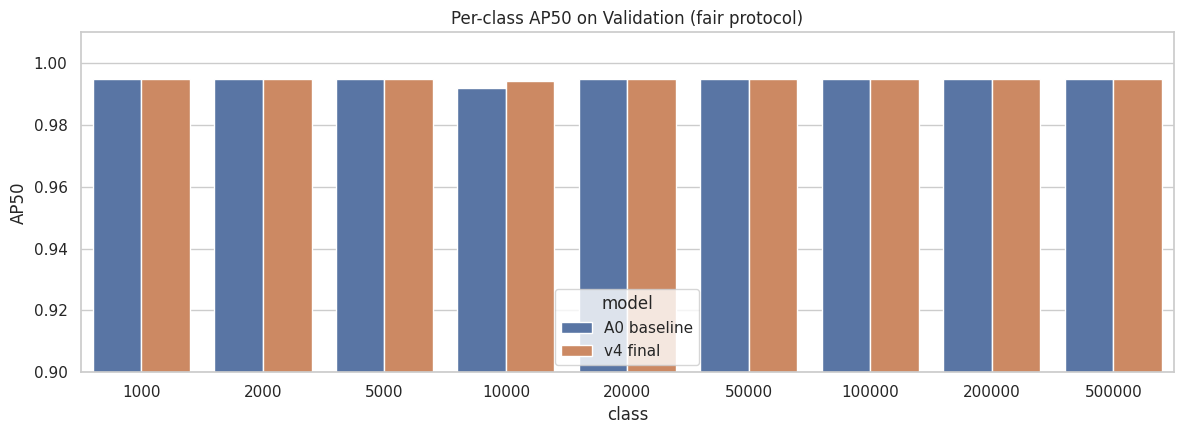

Nhóm class từng lỗi trên camera (delta AP50):


model,class,A0 baseline,v4 final,delta_final_minus_base
1,10000,0.9918,0.9942,0.0024
2,100000,0.9950,0.9950,0.0000
4,20000,0.9950,0.9950,0.0000
5,200000,0.9950,0.9950,0.0000
6,5000,0.9950,0.9950,0.0000
7,50000,0.9950,0.9950,0.0000
8,500000,0.9950,0.9950,0.0000


In [5]:
def per_class_ap_table(metrics_dict: dict, model_name: str) -> pd.DataFrame:
    rows = []
    for name in sorted(CLASS_NAMES, key=lambda x: int(x)):
        rows.append({"model": model_name, "class": name, "AP50": metrics_dict.get(f"AP50_{name}")})
    return pd.DataFrame(rows)


pc = pd.concat([
    per_class_ap_table(base_val, "A0 baseline"),
    per_class_ap_table(final_val, "v4 final"),
], ignore_index=True)

pc_pivot = pc.pivot(index="class", columns="model", values="AP50").reset_index()
pc_pivot["delta_final_minus_base"] = pc_pivot["v4 final"] - pc_pivot["A0 baseline"]
display(pc_pivot.round(4))
pc_pivot.to_csv(EXPORT_DIR / "fair_val_AP50_per_class.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=pc, x="class", y="AP50", hue="model", ax=ax,
            order=sorted(CLASS_NAMES, key=lambda x: int(x)))
ax.set_ylim(0.9, 1.01)
ax.set_title("Per-class AP50 on Validation (fair protocol)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_val_AP50_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

focus = ["5000", "20000", "200000", "100000", "500000", "10000", "50000"]
print("Nhóm class từng lỗi trên camera (delta AP50):")
display(pc_pivot[pc_pivot["class"].isin(focus)].round(4))

## 4. Khóa cấu hình → đánh giá **một lần** trên TEST

Test set Roboflow ≈ 218 ảnh — dùng để báo cáo generalization, **không** để chọn model.

Evaluating baseline on TEST...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 192.6±78.6 MB/s, size: 38.1 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/test/labels.cache... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 65.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 15.1it/s 0.9s0.1s
                   all        218        558      0.995      0.995      0.992      0.919
Speed: 0.3ms preprocess, 2.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Evaluating final v4 on TEST...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 g

,model,split,imgsz,conf,mAP50,mAP50-95,precision,recall,f1
0,A0 YOLOv8n baseline,test,640,0.25,0.9919,0.9193,0.9947,0.9953,0.9950
1,v4 YOLOv8s final,test,640,0.25,0.9918,0.8823,0.9910,0.9965,0.9938


,model,selected_by,val_mAP50,val_mAP50-95,test_mAP50,test_mAP50-95,test_P,test_R,test_F1,note
0,Baseline YOLOv8n (A0),val during train,0.9946,0.9310,0.9919,0.9193,0.9947,0.9953,0.9950,mốc
1,Final YOLOv8s v4,val during iterative improve,0.9949,0.8941,0.9918,0.8823,0.9910,0.9965,0.9938,aug + capacity + real-cam data


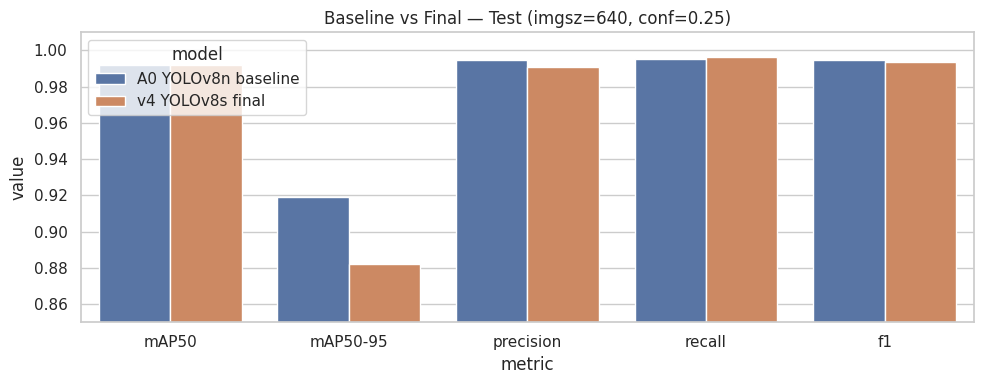

In [6]:
print("Evaluating baseline on TEST...")
base_test = run_val(BASE_PT, TEST_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="A0 YOLOv8n baseline")
print("Evaluating final v4 on TEST...")
final_test = run_val(FINAL_PT, TEST_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="v4 YOLOv8s final")

test_cmp = pd.DataFrame([base_test, final_test])[
    ["model", "split", "imgsz", "conf", "mAP50", "mAP50-95", "precision", "recall", "f1"]
]
display(test_cmp.round(4))
test_cmp.to_csv(EXPORT_DIR / "fair_test_compare_imgsz640.csv", index=False)

# Bảng kiểu báo cáo
report_table = pd.DataFrame([
    {
        "model": "Baseline YOLOv8n (A0)",
        "selected_by": "val during train",
        "val_mAP50": base_val["mAP50"],
        "val_mAP50-95": base_val["mAP50-95"],
        "test_mAP50": base_test["mAP50"],
        "test_mAP50-95": base_test["mAP50-95"],
        "test_P": base_test["precision"],
        "test_R": base_test["recall"],
        "test_F1": base_test["f1"],
        "note": "mốc",
    },
    {
        "model": "Final YOLOv8s v4",
        "selected_by": "val during iterative improve",
        "val_mAP50": final_val["mAP50"],
        "val_mAP50-95": final_val["mAP50-95"],
        "test_mAP50": final_test["mAP50"],
        "test_mAP50-95": final_test["mAP50-95"],
        "test_P": final_test["precision"],
        "test_R": final_test["recall"],
        "test_F1": final_test["f1"],
        "note": "aug + capacity + real-cam data",
    },
])
display(report_table.round(4))
report_table.to_csv(EXPORT_DIR / "report_table_baseline_vs_final.csv", index=False)

melt_t = test_cmp.melt(
    id_vars=["model"], value_vars=["mAP50", "mAP50-95", "precision", "recall", "f1"],
    var_name="metric", value_name="value",
)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=melt_t, x="metric", y="value", hue="model", ax=ax)
ax.set_ylim(0.85, 1.01)
ax.set_title("Baseline vs Final — Test (imgsz=640, conf=0.25)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_test_compare_overview.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.1. (Phụ) Final ở imgsz deploy = 800

In [7]:
final_val_800 = run_val(FINAL_PT, VAL_SPLIT, DEPLOY_IMGSZ, conf=EVAL_CONF, name="v4 final@800")
final_test_800 = run_val(FINAL_PT, TEST_SPLIT, DEPLOY_IMGSZ, conf=EVAL_CONF, name="v4 final@800")
deploy_df = pd.DataFrame([
    {"setting": "v4 fair@640 VAL", **{k: final_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 deploy@800 VAL", **{k: final_val_800[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 fair@640 TEST", **{k: final_test[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 deploy@800 TEST", **{k: final_test_800[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
])
display(deploy_df.round(4))
deploy_df.to_csv(EXPORT_DIR / "final_640_vs_800.csv", index=False)

Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3818.5±499.3 MB/s, size: 40.0 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/valid/labels.cache... 439 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 439/439 131.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 6.7it/s 4.2s0.1s
                   all        439       1074      0.993      0.999      0.994       0.89
Speed: 0.5ms preprocess, 7.6ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0

,setting,mAP50,mAP50-95,precision,recall,f1
0,v4 fair@640 VAL,0.9949,0.8941,0.9960,0.9972,0.9966
1,v4 deploy@800 VAL,0.9941,0.8900,0.9934,0.9991,0.9962
2,v4 fair@640 TEST,0.9918,0.8823,0.9910,0.9965,0.9938
3,v4 deploy@800 TEST,0.9913,0.8769,0.9881,0.9965,0.9923


## 5. Tối ưu ngưỡng confidence trên VAL theo chi phí FP/FN

Coi `confidence` như điểm xếp hạng. Chọn ngưỡng $\tau$ trên **validation** để tối thiểu hóa chi phí gần đúng:

$$
\mathrm{Cost}(\tau)= c_{FP}\,(1-P(\tau)) + c_{FN}\,(1-R(\tau))
$$

(proxy khi không đếm tuyệt đối FP/FN theo matching thủ công).  
Mặc định: bỏ sót đắt hơn báo nhầm → $c_{FN}=3$, $c_{FP}=1$.

Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3486.4±1127.7 MB/s, size: 36.8 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/valid/labels.cache... 439 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 439/439 184.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 16.7it/s 1.7s0.1s
                   all        439       1074      0.989      0.995      0.995      0.931
Speed: 0.3ms preprocess, 2.2ms inference, 0.0ms loss, 0.4ms postprocess per image
A0 baseline conf=0.05 | P=0.989 R=0.995 cost=0.0246
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradien

,model,conf,precision,recall,f1,mAP50,cost_proxy
5,A0 baseline,0.3,0.989490,0.998123,0.993788,0.994649,0.016141
9,v4 final,0.5,0.997197,0.997268,0.997233,0.992759,0.010999


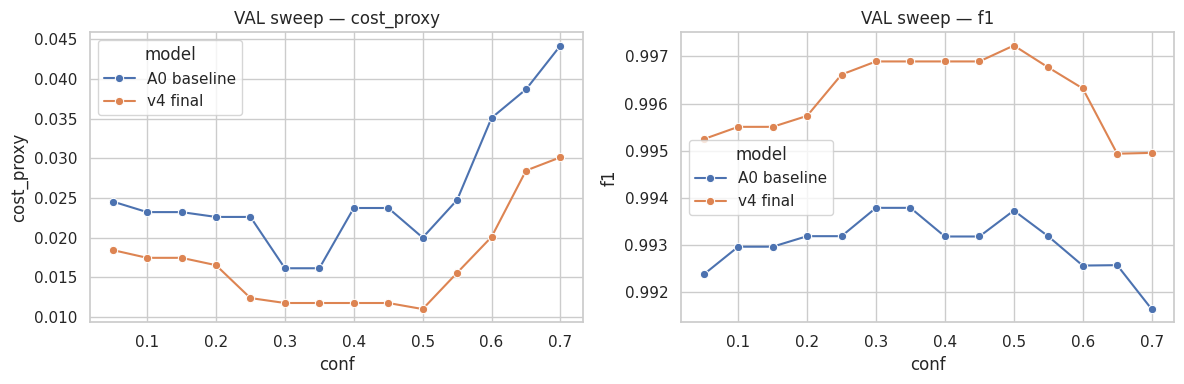


Khóa τ*=0.50 cho final → đánh giá TEST một lần
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2555.1±918.2 MB/s, size: 47.5 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/test/labels.cache... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 101.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 9.3it/s 1.5s0.1s
                   all        218        558      0.991      0.997      0.992      0.882
Speed: 0.3ms preprocess, 4.9ms inference, 0.0ms loss, 0.4ms postprocess per image


,model,conf,mAP50,precision,recall,f1
0,v4@τ*=0.5,0.5,0.9918,0.9911,0.9965,0.9938


In [8]:
C_FP = 1.0
C_FN = 3.0
CONF_GRID = np.round(np.arange(0.05, 0.75, 0.05), 2)

RUN_CONF_SWEEP = True  # đặt False nếu muốn bỏ qua (mất thời gian)


def sweep_conf(weights: Path, model_name: str, imgsz: int = FAIR_IMGSZ) -> pd.DataFrame:
    rows = []
    model = YOLO(str(weights))
    for conf in CONF_GRID:
        m = model.val(
            data=str(DATA_YAML),
            split=VAL_SPLIT,
            imgsz=imgsz,
            conf=float(conf),
            device=DEVICE,
            plots=False,
            verbose=False,
        )
        met = extract_metrics(m)
        cost = C_FP * (1.0 - met["precision"]) + C_FN * (1.0 - met["recall"])
        rows.append({
            "model": model_name,
            "conf": float(conf),
            "precision": met["precision"],
            "recall": met["recall"],
            "f1": met["f1"],
            "mAP50": met["mAP50"],
            "cost_proxy": cost,
        })
        print(f"{model_name} conf={conf:.2f} | P={met['precision']:.3f} R={met['recall']:.3f} cost={cost:.4f}")
    return pd.DataFrame(rows)


if RUN_CONF_SWEEP:
    sweep_base = sweep_conf(BASE_PT, "A0 baseline")
    sweep_final = sweep_conf(FINAL_PT, "v4 final")
    sweep_all = pd.concat([sweep_base, sweep_final], ignore_index=True)
    sweep_all.to_csv(EXPORT_DIR / "conf_sweep_val.csv", index=False)

    best_rows = []
    for name, df in [("A0 baseline", sweep_base), ("v4 final", sweep_final)]:
        best = df.loc[df["cost_proxy"].idxmin()]
        best_rows.append(best)
        print(f"→ {name}: τ*={best['conf']:.2f} | cost={best['cost_proxy']:.4f} | P={best['precision']:.3f} R={best['recall']:.3f}")
    best_df = pd.DataFrame(best_rows)
    display(best_df)
    best_df.to_csv(EXPORT_DIR / "conf_best_on_val.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, df, ax in [
        ("cost_proxy", sweep_all, axes[0]),
        ("f1", sweep_all, axes[1]),
    ]:
        sns.lineplot(data=df, x="conf", y=name, hue="model", marker="o", ax=ax)
        ax.set_title(f"VAL sweep — {name}")
    plt.tight_layout()
    plt.savefig(EXPORT_DIR / "fig_conf_sweep_val.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Khóa τ* của final → đo 1 lần trên TEST
    tau_star = float(best_df.loc[best_df["model"] == "v4 final", "conf"].iloc[0])
    print(f"\nKhóa τ*={tau_star:.2f} cho final → đánh giá TEST một lần")
    final_test_tau = run_val(FINAL_PT, TEST_SPLIT, FAIR_IMGSZ, conf=tau_star, name=f"v4@τ*={tau_star}")
    display(pd.DataFrame([final_test_tau])[["model", "conf", "mAP50", "precision", "recall", "f1"]].round(4))
    pd.DataFrame([final_test_tau]).to_csv(EXPORT_DIR / "final_test_at_tau_star.csv", index=False)
else:
    print("Bỏ qua conf sweep.")

## 6. Đường cong học (train history)

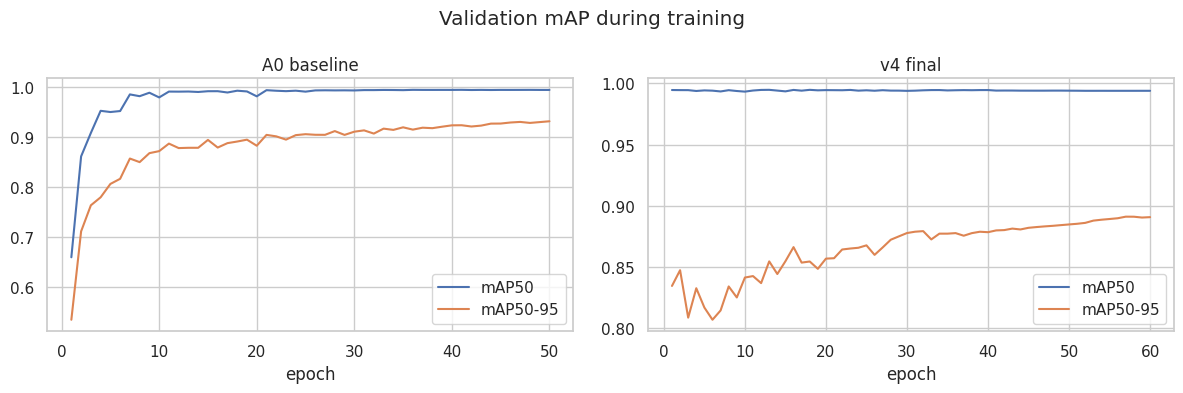

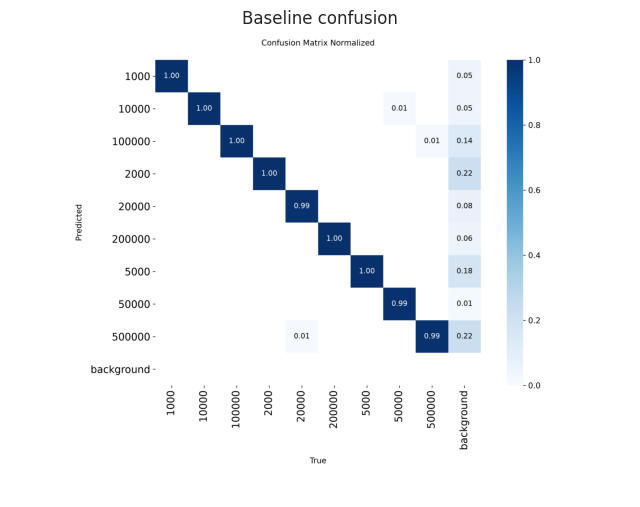

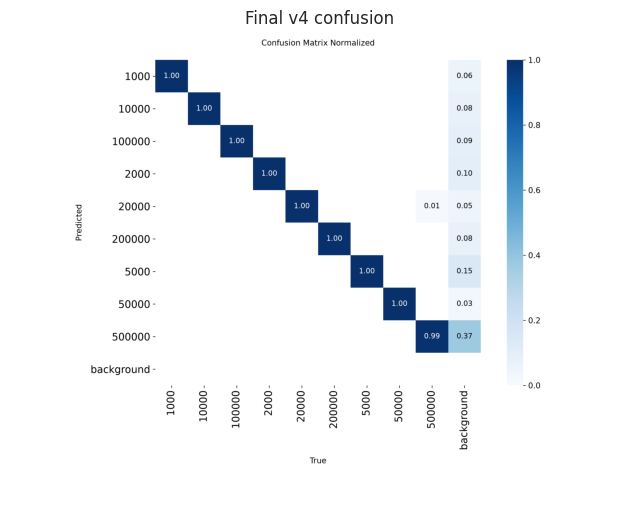

In [9]:
def load_history(run_name: str) -> pd.DataFrame | None:
    p = PROJECT_DIR / "runs" / "detect" / run_name / "results.csv"
    if not p.exists():
        print("Thiếu", p)
        return None
    df = pd.read_csv(p)
    df.columns = [c.strip() for c in df.columns]
    return df


hist_base = load_history("vn_currency_yolov8n_baseline")
hist_final = load_history("vn_currency_yolov8s_v4")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, label, ax in [
    (hist_base, "A0 baseline", axes[0]),
    (hist_final, "v4 final", axes[1]),
]:
    if hist is None:
        ax.set_title(f"{label}: missing results.csv")
        continue
    epoch = hist["epoch"] if "epoch" in hist.columns else hist.iloc[:, 0]
    map50 = next((c for c in hist.columns if "mAP50(B)" in c or ("mAP50" in c and "95" not in c)), None)
    map5095 = next((c for c in hist.columns if "mAP50-95" in c), None)
    if map50:
        ax.plot(epoch, hist[map50], label="mAP50")
    if map5095:
        ax.plot(epoch, hist[map5095], label="mAP50-95")
    ax.set_title(label)
    ax.set_xlabel("epoch")
    ax.legend()
plt.suptitle("Validation mAP during training")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_train_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Hiển thị confusion / PR đã xuất sẵn nếu có
for run, title in [
    ("vn_currency_yolov8n_baseline", "Baseline confusion"),
    ("vn_currency_yolov8s_v4", "Final v4 confusion"),
]:
    p = PROJECT_DIR / "runs" / "detect" / run / "confusion_matrix_normalized.png"
    if p.exists():
        plt.figure(figsize=(8, 7))
        plt.imshow(Image.open(p))
        plt.axis("off")
        plt.title(title)
        plt.show()

## 7. So sánh qualitative trên cùng ảnh validation

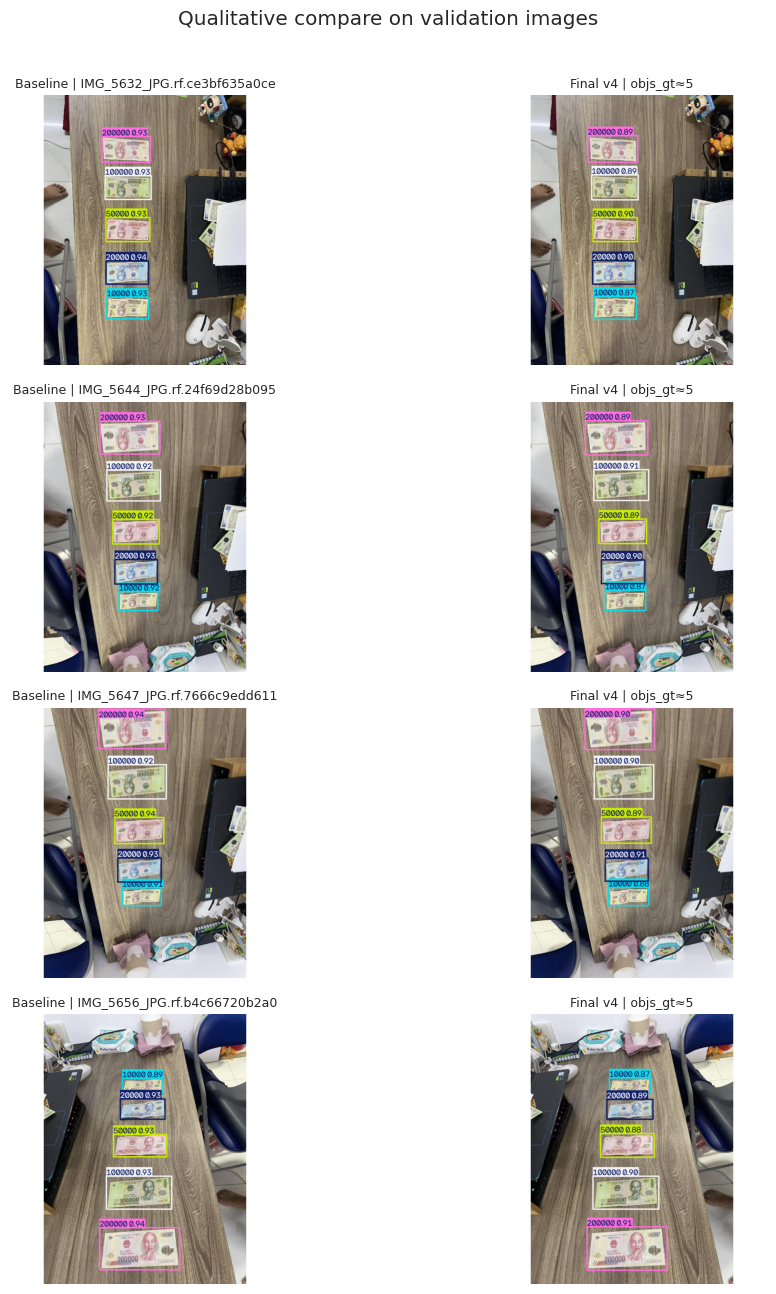

In [10]:
val_img_dir = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "valid" / "images"
val_lbl_dir = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "valid" / "labels"
val_images = sorted([p for p in val_img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])


def count_obj(stem: str) -> int:
    lp = val_lbl_dir / f"{stem}.txt"
    if not lp.exists():
        return 0
    return sum(1 for ln in lp.read_text().splitlines() if ln.strip())


# ưu tiên ảnh nhiều tờ
hard = sorted([(count_obj(p.stem), p) for p in val_images], key=lambda x: -x[0])
sample = [p for n, p in hard if n >= 2][:4]
if len(sample) < 4:
    sample = random.sample(val_images, k=min(4, len(val_images)))

base_model = YOLO(str(BASE_PT))
final_model = YOLO(str(FINAL_PT))

fig, axes = plt.subplots(len(sample), 2, figsize=(12, 3.2 * len(sample)))
if len(sample) == 1:
    axes = np.array([axes])

for i, path in enumerate(sample):
    b = base_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=EVAL_CONF, device=DEVICE, verbose=False)[0]
    f = final_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=EVAL_CONF, device=DEVICE, verbose=False)[0]
    axes[i, 0].imshow(b.plot()[:, :, ::-1])
    axes[i, 0].set_title(f"Baseline | {path.name[:28]}", fontsize=9)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(f.plot()[:, :, ::-1])
    axes[i, 1].set_title(f"Final v4 | objs_gt≈{count_obj(path.stem)}", fontsize=9)
    axes[i, 1].axis("off")

plt.suptitle("Qualitative compare on validation images", y=1.01)
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_qualitative_val.png", dpi=140, bbox_inches="tight")
plt.show()

### 7.1. Ảnh cam thật (domain demo) — nếu có `real_cam_yolo`

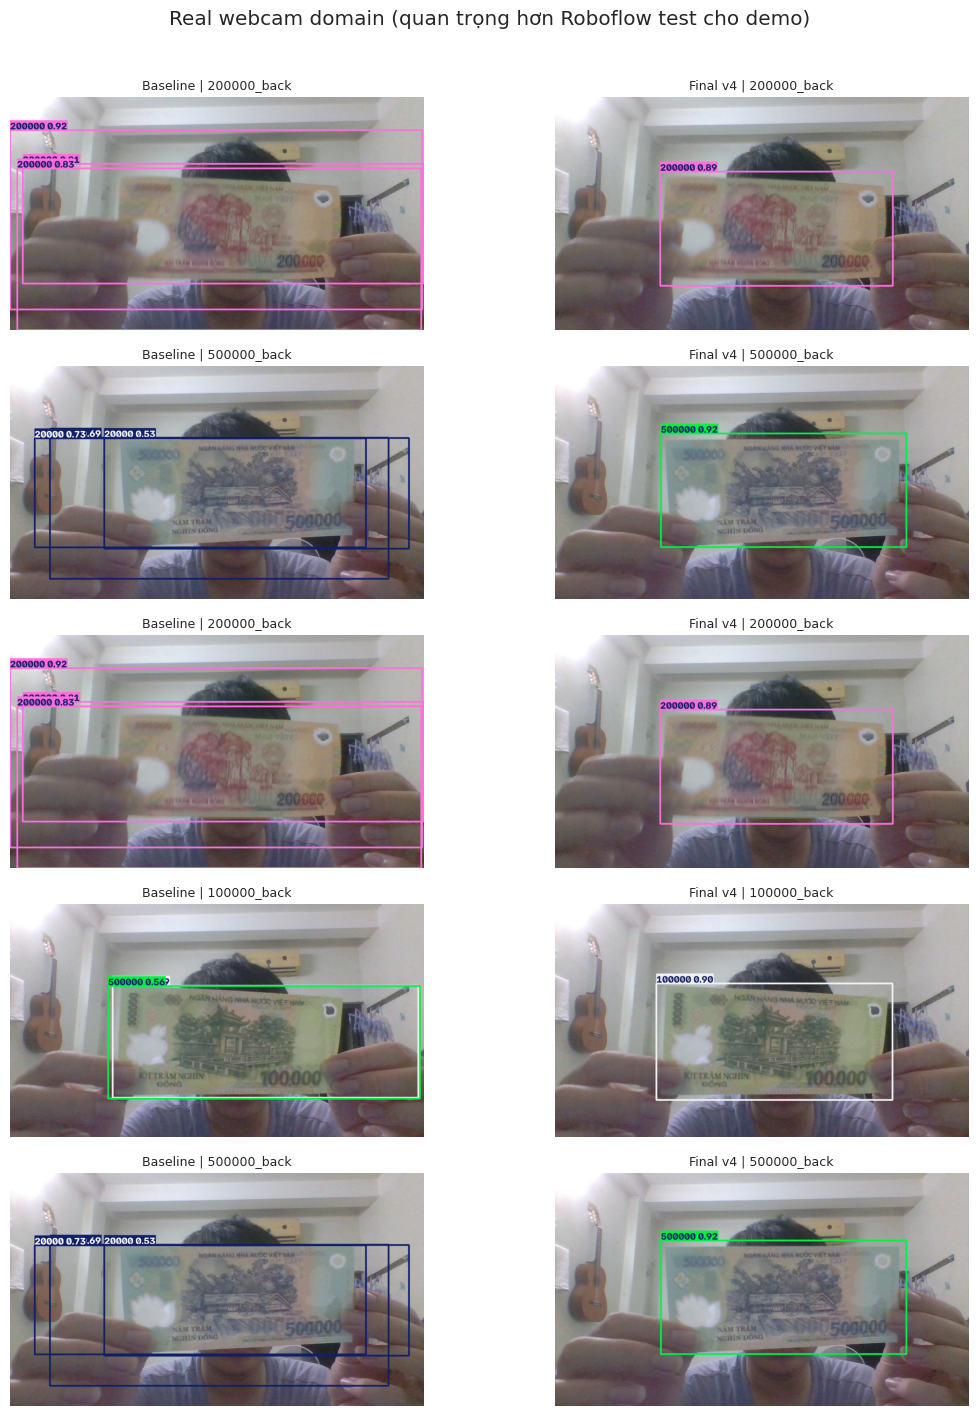

In [11]:
real_dir = PROJECT_DIR / "datasets" / "real_cam_yolo" / "images"
if real_dir.exists():
    real_imgs = sorted(real_dir.glob("*.jpg"))
    # ưu tiên các class từng khó
    prefer = ["200000", "5000", "20000", "100000", "50000"]
    chosen = []
    for key in prefer:
        hits = [p for p in real_imgs if p.name.startswith(key)]
        chosen.extend(hits[:1])
    chosen = chosen[:6] or real_imgs[:6]

    fig, axes = plt.subplots(len(chosen), 2, figsize=(12, 2.8 * len(chosen)))
    if len(chosen) == 1:
        axes = np.array([axes])
    for i, path in enumerate(chosen):
        b = base_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
        f = final_model.predict(str(path), imgsz=DEPLOY_IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
        axes[i, 0].imshow(b.plot()[:, :, ::-1]); axes[i, 0].set_title(f"Baseline | {path.stem}", fontsize=9); axes[i, 0].axis("off")
        axes[i, 1].imshow(f.plot()[:, :, ::-1]); axes[i, 1].set_title(f"Final v4 | {path.stem}", fontsize=9); axes[i, 1].axis("off")
    plt.suptitle("Real webcam domain (quan trọng hơn Roboflow test cho demo)", y=1.01)
    plt.tight_layout()
    plt.savefig(EXPORT_DIR / "fig_qualitative_real_cam.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("Không có datasets/real_cam_yolo/images — bỏ qua.")

## 8. Tổng kết nhận xét cho báo cáo

In [12]:
summary = {
    "protocol": {
        "data_yaml": str(DATA_YAML),
        "fair_imgsz": FAIR_IMGSZ,
        "eval_conf": EVAL_CONF,
        "test_images_note": "Roboflow test ≈ 218 images — hạn chế mẫu",
    },
    "baseline_val": {k: base_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "final_val": {k: final_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "baseline_test": {k: base_test[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "final_test": {k: final_test[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "delta_test_mAP50": final_test["mAP50"] - base_test["mAP50"],
    "delta_test_mAP50-95": final_test["mAP50-95"] - base_test["mAP50-95"],
    "improvements": [
        "YOLOv8n → YOLOv8s (tăng capacity phân lớp mệnh giá gần nhau)",
        "Augment mạnh: scale/mosaic/mixup/copy-paste/erasing + xoay 90°",
        "Oversample class khó (5k/20k/200k/...)",
        "Fine-tune đa vòng v2→v3→v4",
        "Bổ sung ảnh cam thật mờ/nền rối (front/back) vào train",
        "Demo: temporal hold ~1s giảm nhấp nháy",
    ],
    "limitations": [
        "Roboflow val/test đã rất cao từ baseline → delta metric trên split này có thể nhỏ; cải tiến chủ yếu lộ trên camera thật",
        "Một số cặp màu gần (5k↔20k, 200k↔10000/500k) vẫn có thể nhầm trong điều kiện ánh sáng xấu",
        "Ảnh cam thật vẫn ít (18 gốc) dù đã augment",
        "Thiếu class 500đ so với README 10 mệnh giá",
    ],
}

with open(EXPORT_DIR / "compare_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("===== KẾT LUẬN NGẮN =====")
print(f"VAL  mAP50:  baseline={base_val['mAP50']:.4f} | final={final_val['mAP50']:.4f} | Δ={final_val['mAP50']-base_val['mAP50']:+.4f}")
print(f"TEST mAP50:  baseline={base_test['mAP50']:.4f} | final={final_test['mAP50']:.4f} | Δ={final_test['mAP50']-base_test['mAP50']:+.4f}")
print(f"TEST mAP50-95: baseline={base_test['mAP50-95']:.4f} | final={final_test['mAP50-95']:.4f} | Δ={final_test['mAP50-95']-base_test['mAP50-95']:+.4f}")
print("\nCách viết báo cáo:")
print("1) Nêu protocol (cùng split, imgsz=640, conf cố định) — không chọn model theo test.")
print("2) Đưa bảng report_table_baseline_vs_final.csv + hình fig_*.png.")
print("3) Nhấn mạnh: trên Roboflow metric đã bão hòa; lợi ích v4 nằm ở domain cam thật / góc / nền rối (kèm fig_qualitative_real_cam).")
print("4) Mục cải tiến = data + capacity + quyết định (conf sweep / hold), không chỉ 'train thêm epoch'.")
print("5) Nêu hạn chế còn lại (cặp nhầm màu, ít ảnh cam, thiếu class 500).")
print("\nĐã xuất toàn bộ vào:", EXPORT_DIR)

===== KẾT LUẬN NGẮN =====
VAL  mAP50:  baseline=0.9946 | final=0.9949 | Δ=+0.0003
TEST mAP50:  baseline=0.9919 | final=0.9918 | Δ=-0.0001
TEST mAP50-95: baseline=0.9193 | final=0.8823 | Δ=-0.0371

Cách viết báo cáo:
1) Nêu protocol (cùng split, imgsz=640, conf cố định) — không chọn model theo test.
2) Đưa bảng report_table_baseline_vs_final.csv + hình fig_*.png.
3) Nhấn mạnh: trên Roboflow metric đã bão hòa; lợi ích v4 nằm ở domain cam thật / góc / nền rối (kèm fig_qualitative_real_cam).
4) Mục cải tiến = data + capacity + quyết định (conf sweep / hold), không chỉ 'train thêm epoch'.
5) Nêu hạn chế còn lại (cặp nhầm màu, ít ảnh cam, thiếu class 500).

Đã xuất toàn bộ vào: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/compare_exports
